# Track a moving Blob with SAM2
Colour-independent tracking: click the ball once on one frame, and SAM 2 (Segment Anything Model 2, via the `ultralytics` package) segments and follows it through the rest of the video. Then the ball speed in m/s is computed as in `track_ball.ipynb`. Runs on CUDA (e.g. Colab), Apple Metal (`mps`) or CPU.

## Step 1: Load the video
Reads all frames into memory and selects the compute device.

In [9]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path

VIDEO = Path("/Users/souvikmandal/Documents/S06_Teaching_Mentoring_Talks/LS100/2026_Sem2/data/raw/water-polo_maya/01-F-01-TL-Back-2_trimmed.mp4")
CROP_OFFSET = (500, 400)  # top_left used when trimming
BALL_DIAMETER_M = 0.21

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

cap = cv2.VideoCapture(str(VIDEO))
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(f)
fps = cap.get(cv2.CAP_PROP_FPS)
cap.release()
H, W = frames[0].shape[:2]
print(f"{len(frames)} frames, {W}x{H}, {fps:.2f} fps, device={DEVICE}")

222 frames, 1420x400, 59.94 fps, device=mps


## Step 2: Choose the frame and click point
Set `PROMPT_FRAME` to a frame where the ball is clearly visible, and `PROMPT_POINT` to `(x, y)` pixel coordinates on the ball (read from the grid). SAM 2 tracks forward from this frame, so choose the earliest frame you need, for example just before release. Re-run this cell until the red cross sits on the ball.

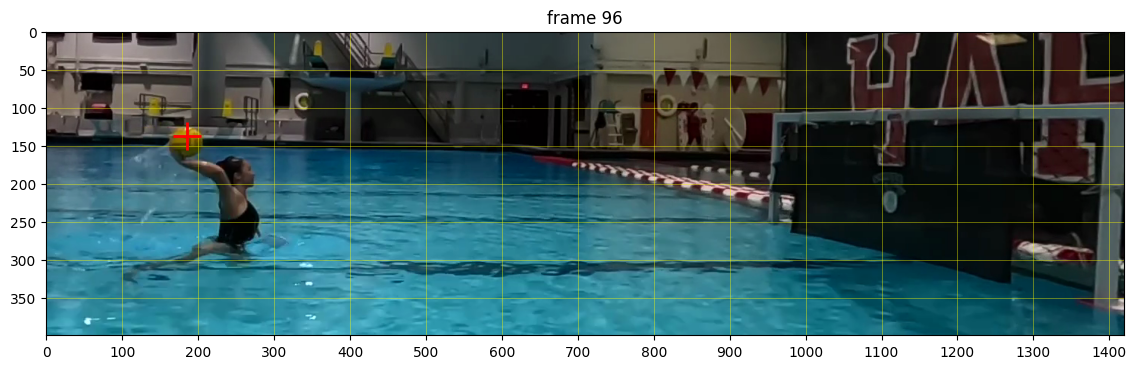

In [2]:
PROMPT_FRAME = 96
PROMPT_POINT = (185, 137)  # (x, y) on the ball, in trimmed-frame pixels

fig, ax = plt.subplots(figsize=(14, 14 * H / W))
ax.imshow(cv2.cvtColor(frames[PROMPT_FRAME], cv2.COLOR_BGR2RGB))
ax.set_xticks(range(0, W + 1, 100)); ax.set_yticks(range(0, H + 1, 50))
ax.grid(True, color="yellow", alpha=0.4, linewidth=0.7)
ax.plot(*PROMPT_POINT, "r+", ms=20, mew=2)
ax.set_title(f"frame {PROMPT_FRAME}")
plt.show()

## Step 3: Run SAM 2 on the video
Writes the frames from `PROMPT_FRAME` onward to a temporary clip and runs the SAM 2 video predictor with the clicked point as a positive prompt. The model weights (`SAM2_WEIGHTS`) are downloaded automatically on first use; `sam2.1_t.pt` (tiny) is faster, `sam2.1_b.pt` (base) is more accurate. If the chosen device fails, it falls back to CPU. The result is one segmentation mask per frame.

In [3]:
import tempfile
from ultralytics.models.sam import SAM2VideoPredictor

SAM2_WEIGHTS = "sam2.1_b.pt"

clip_path = Path(tempfile.mkdtemp()) / "clip.mp4"
writer = cv2.VideoWriter(str(clip_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
for f in frames[PROMPT_FRAME:]:
    writer.write(f)
writer.release()

def run_sam2(device):
    overrides = dict(conf=0.25, task="segment", mode="predict", imgsz=1024, model=SAM2_WEIGHTS, device=device, save=False, verbose=False)
    predictor = SAM2VideoPredictor(overrides=overrides)
    return predictor(source=str(clip_path), points=[list(PROMPT_POINT)], labels=[1])

try:
    results = run_sam2(DEVICE)
except Exception as e:
    print(f"{DEVICE} failed ({type(e).__name__}: {e}); retrying on CPU")
    results = run_sam2("cpu")

print(f"{len(results)} frames segmented")

Ultralytics 8.4.27 🚀 Python-3.12.12 torch-2.11.0 MPS (Apple M2 Max)
WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

126 frames segmented


## Step 4: Masks to ball positions and a visual check
For each frame, takes the mask's centroid as the ball position and its area-equivalent diameter $d = 2\sqrt{A/\pi}$ as the ball size in pixels. Frames where SAM 2 returns no mask are `NaN`. The plot shows the mask outline on sample frames and the mask area over time; a sudden jump in area or position means the mask has drifted onto something else (hand, splash, goal).

masks found in 26 / 126 frames


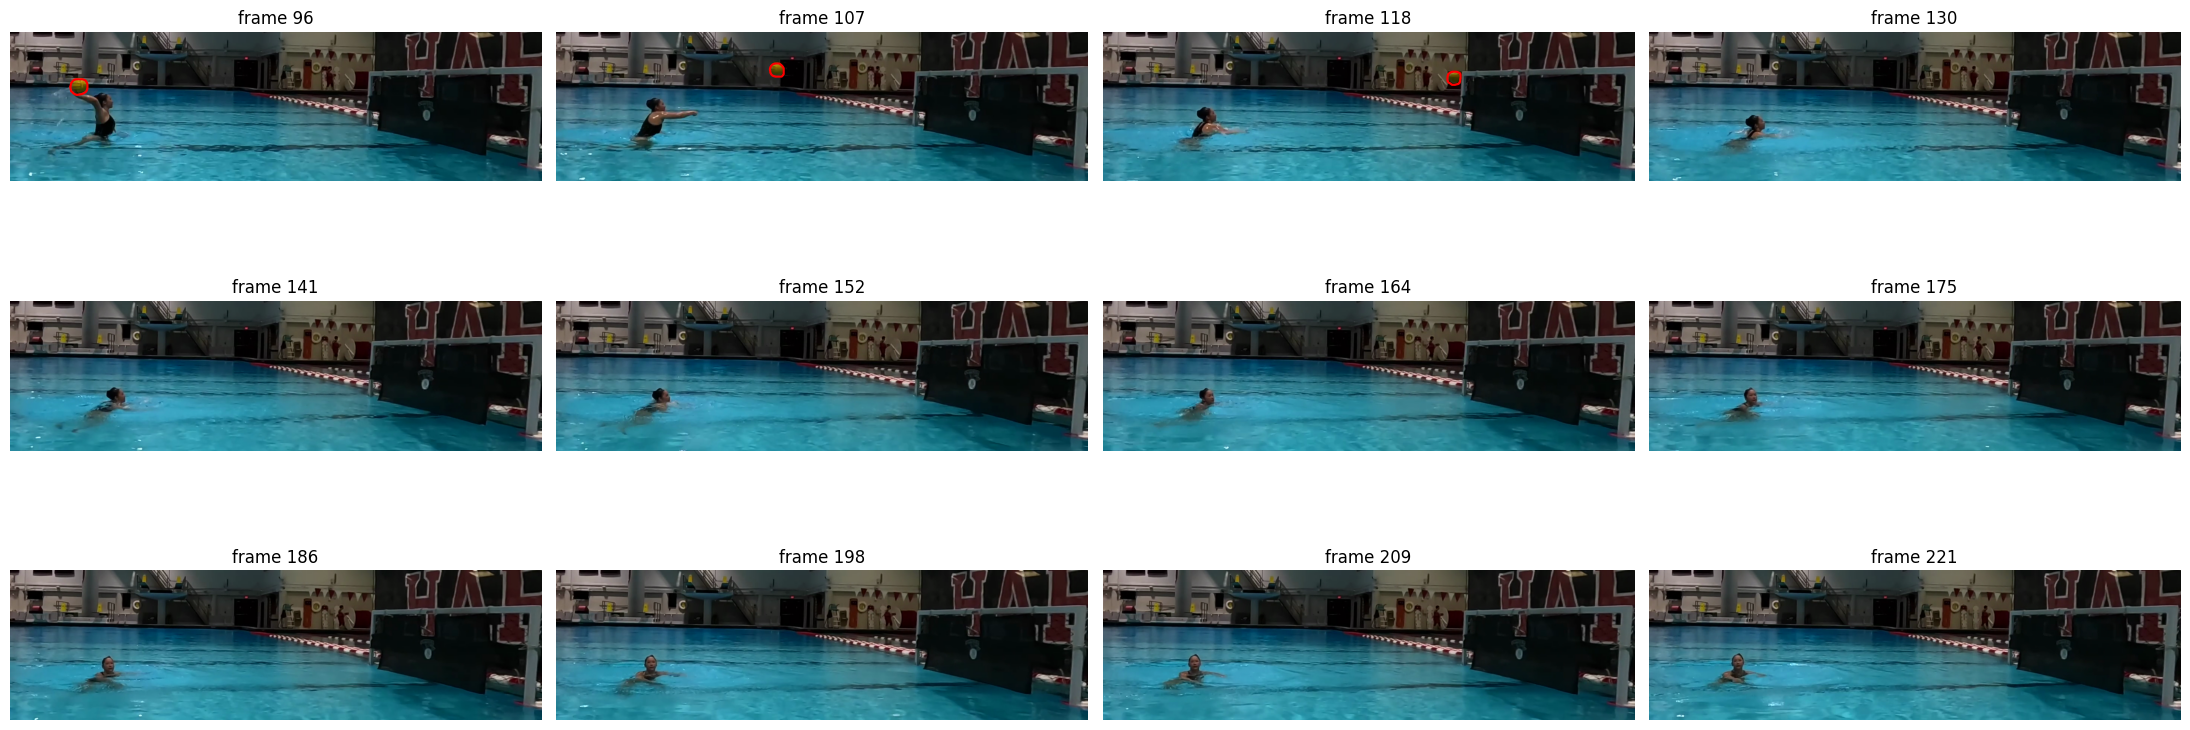

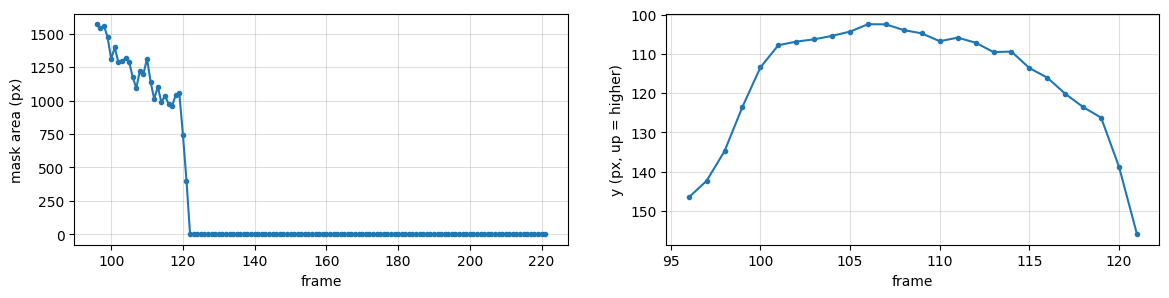

In [4]:
rows, mask_by_frame = [], {}
for k, r in enumerate(results):
    fr = PROMPT_FRAME + k
    m = None
    if r.masks is not None and len(r.masks.data):
        m = r.masks.data[0].cpu().numpy() > 0.5
        if m.shape != (H, W):
            m = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0
    if m is not None and m.any():
        ys, xs = np.nonzero(m)
        area = m.sum()
        rows.append((fr, xs.mean(), ys.mean(), area, 2 * np.sqrt(area / np.pi)))
        mask_by_frame[fr] = m
    else:
        rows.append((fr, np.nan, np.nan, 0, np.nan))

sam = pd.DataFrame(rows, columns=["frame", "x", "y", "area", "d_px"])
print(f"masks found in {sam.x.notna().sum()} / {len(sam)} frames")

shown = np.linspace(PROMPT_FRAME, sam.frame.max(), 12).astype(int)
fig, axes = plt.subplots(3, 4, figsize=(22, 9))
for ax, i in zip(axes.ravel(), shown):
    ax.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
    if i in mask_by_frame:
        ax.contour(mask_by_frame[i], levels=[0.5], colors="red", linewidths=1.5)
    ax.set_title(f"frame {i}"); ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].plot(sam.frame, sam.area, ".-"); axes[0].set_ylabel("mask area (px)")
axes[1].plot(sam.frame, sam.y, ".-"); axes[1].invert_yaxis(); axes[1].set_ylabel("y (px, up = higher)")
for a in axes:
    a.set_xlabel("frame"); a.grid(alpha=.4)
plt.show()

## Step 5: Ball speed in m/s
The ball's known diameter ($0.21$ m) gives the scale, but the camera looks along the throw, so the ball's apparent size shrinks as it flies away. A single constant scale would therefore underestimate its later speed. Instead, the scale is taken per frame from a linear trend of the mask diameter: $X=(x-c_x)\,D/d$, $Y=-(y-c_y)\,D/d$ in metres, where $D$ is the ball diameter and $d$ its diameter in pixels. Frames where the mask is much smaller than typical (ball partly hidden) are excluded, and the release frame is the first frame where the ball moves faster than `RELEASE_PX_PER_FRAME`.

Free flight is fitted as $X(t)=X_0+v_xt$ and $Y(t)=Y_0+v_yt-\tfrac12 g_{fit}t^2$. `g_fit` should be near 9.81 m/s² if the scale and track are good. The reported speed is in the image plane. If you know the camera focal length in pixels (`FOCAL_PX`), the depth $Z=f\,D/d$ is also computed, giving the 3D speed. Air drag is ignored, and the camera is assumed level with its principal point at the image centre. Set `RELEASE_FRAME`/`END_FRAME` to override the automatic choice.

Ball diameter 42.1 px at release -> 35.1 px at the end (1.20x change in size)
Flight frames 99-119 (21 points, 0.33 s)
Release speed (image plane): 12.1 m/s (44 km/h)  vx=12.1, vy=1.2 m/s, angle=5 deg
Fitted g: 7.5 m/s^2 (expected 9.81)
Fit residual (RMS): 9 mm in y, 27 mm in x


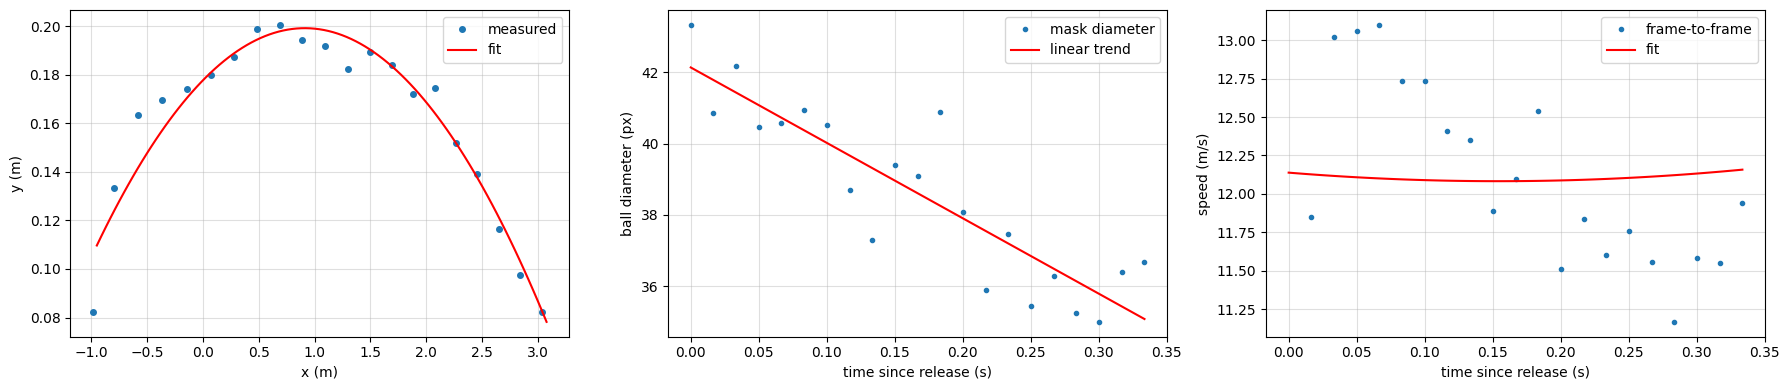

In [8]:
RELEASE_PX_PER_FRAME = 15   # px/frame; release = first frame faster than this
MIN_AREA_FRAC = 0.7         # drop frames whose mask is smaller than this fraction of the median area
RELEASE_FRAME, END_FRAME = 99, 119  # None = automatic; here set by eye from the speed plot (hand contact at start, goal impact at end)
FOCAL_PX = None             # camera focal length in pixels of the ORIGINAL frame; set it to also get depth motion and 3D speed
PRINCIPAL_PT = (1920 / 2 - CROP_OFFSET[0], 1080 / 2 - CROP_OFFSET[1])  # image centre of the untrimmed frame, in trimmed coordinates

good = sam.x.notna() & (sam.area >= MIN_AREA_FRAC * sam.area.median())
trk = sam[good].copy()
trk["step"] = np.hypot(trk.x.diff(), trk.y.diff())

rel = RELEASE_FRAME if RELEASE_FRAME is not None else int(trk.frame[trk.step > RELEASE_PX_PER_FRAME].iloc[0])
end = END_FRAME if END_FRAME is not None else int(trk.frame.iloc[-1])
fl = trk[(trk.frame >= rel) & (trk.frame <= end)].copy()
t = (fl.frame - rel) / fps

# The ball's apparent size changes as it moves toward/away from the camera, so use a per-frame scale
# from a smoothed diameter trend instead of one constant scale.
d_s = np.polyval(np.polyfit(t, fl.d_px, 1), t)
fl["d_s"] = d_s
m_per_px = BALL_DIAMETER_M / d_s
fl["X"] = (fl.x - PRINCIPAL_PT[0]) * m_per_px
fl["Y"] = -(fl.y - PRINCIPAL_PT[1]) * m_per_px  # y up
fl["Z"] = FOCAL_PX * m_per_px if FOCAL_PX else 0.0  # depth from the camera

px_, py_, pz_ = np.polyfit(t, fl.X, 1), np.polyfit(t, fl.Y, 2), np.polyfit(t, fl.Z, 1)
vx0, vy0, vz0, g_fit = px_[0], py_[1], pz_[0], -2 * py_[0]
v_lat = np.hypot(vx0, vy0)
v0 = np.sqrt(vx0**2 + vy0**2 + vz0**2)

v_raw = np.sqrt(fl.X.diff()**2 + fl.Y.diff()**2 + fl.Z.diff()**2) * fps
tt = np.linspace(0, t.max(), 100)
v_fit = np.sqrt(vx0**2 + (vy0 - g_fit * tt)**2 + vz0**2)

print(f"Ball diameter {fl.d_s.iloc[0]:.1f} px at release -> {fl.d_s.iloc[-1]:.1f} px at the end ({fl.d_s.iloc[0] / fl.d_s.iloc[-1]:.2f}x change in size)")
print(f"Flight frames {rel}-{end} ({len(fl)} points, {t.max():.2f} s)")
print(f"Release speed (image plane): {v_lat:.1f} m/s ({v_lat * 3.6:.0f} km/h)  vx={vx0:.1f}, vy={vy0:.1f} m/s, angle={np.degrees(np.arctan2(vy0, vx0)):.0f} deg")
if FOCAL_PX:
    print(f"Release speed (3D): {v0:.1f} m/s ({v0 * 3.6:.0f} km/h)  vz={vz0:.1f} m/s (positive = away from camera)")
print(f"Fitted g: {g_fit:.1f} m/s^2 (expected 9.81)")
print(f"Fit residual (RMS): {np.sqrt(np.mean((np.polyval(py_, t) - fl.Y) ** 2)) * 1000:.0f} mm in y, "
      f"{np.sqrt(np.mean((np.polyval(px_, t) - fl.X) ** 2)) * 1000:.0f} mm in x")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(fl.X, fl.Y, "o", ms=4, label="measured")
axes[0].plot(np.polyval(px_, tt), np.polyval(py_, tt), "r-", label="fit")
axes[0].set_xlabel("x (m)"); axes[0].set_ylabel("y (m)"); axes[0].legend(); axes[0].grid(alpha=.4)
axes[1].plot(t, fl.d_px, ".", label="mask diameter"); axes[1].plot(t, fl.d_s, "r-", label="linear trend")
axes[1].set_xlabel("time since release (s)"); axes[1].set_ylabel("ball diameter (px)"); axes[1].legend(); axes[1].grid(alpha=.4)
axes[2].plot(t, v_raw, ".", label="frame-to-frame"); axes[2].plot(tt, v_fit, "r-", label="fit")
axes[2].set_xlabel("time since release (s)"); axes[2].set_ylabel("speed (m/s)"); axes[2].legend(); axes[2].grid(alpha=.4)
plt.tight_layout(); plt.show()